# KERALA RAINFALL & CLIMATE PATTERN ANALYSIS USING PYTHON

## INTRODUCTION

Rainfall is one of the most important climatic factors influencing agriculture, water resources, ecosystems, and disaster management in Kerala. The state receives rainfall mainly through the Southwest Monsoon and Northeast Monsoon, and rainfall patterns can vary across months, years, and districts.

This project uses Exploratory Data Analysis (EDA) with Python to understand rainfall patterns in Kerala. The analysis focuses on rainfall distribution, yearly and monthly variation, seasonal behavior, monsoon patterns, district-wise differences, and extreme rainfall events.

The objective is to transform raw rainfall observations into meaningful insights using Pandas, NumPy, Matplotlib, and Seaborn.

## ABOUT THE DATASET

The dataset contains manual daily rainfall observations for Kerala for the period 2021–2025.

Important variables used in this project include:

- **Data Acquisition Time** – date and time of the rainfall observation
- **Station** – rainfall observation station
- **District** – district where the observation was recorded
- **Tehsil** – administrative area
- **Block** – block associated with the observation
- **Latitude / Longitude** – geographical location
- **Manual Daily Rainfall (mm)** – recorded daily rainfall in millimetres

Additional features such as Year, Month, Month Name, Day, and Season are created during the analysis.

## IMPORTING LIBRARIES

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## IMPORTING DATASET

In [17]:
df = pd.read_csv("rainfall_manual_daily_kerala_sw_kl_2021_2025.csv")

df.head()

,SlNo,Station,Agency,State LGD Code,State,District LGD Code,District,Tehsil,Block,Village,River,Basin,Tributary,Subtributary,SubSubtributary,Local River,Latitude,Longitude,Data Acquisition Time,Manual Daily Rainfall (mm)
0,1,Achencoil,Kerala SW,32,Kerala,559,Kollam,ANCHAL,ANCHAL,Ariyankavu,Tapi,Tapi,Balki,-,-,Achencoil,9.092378,77.122,06-01-2021 08:30,2.0
1,2,Achencoil,Kerala SW,32,Kerala,559,Kollam,ANCHAL,ANCHAL,Ariyankavu,Tapi,Tapi,Balki,-,-,Achencoil,9.092378,77.122,07-01-2021 08:30,23.0
2,3,Achencoil,Kerala SW,32,Kerala,559,Kollam,ANCHAL,ANCHAL,Ariyankavu,Tapi,Tapi,Balki,-,-,Achencoil,9.092378,77.122,08-01-2021 08:30,0.4
3,4,Achencoil,Kerala SW,32,Kerala,559,Kollam,ANCHAL,ANCHAL,Ariyankavu,Tapi,Tapi,Balki,-,-,Achencoil,9.092378,77.122,09-01-2021 08:30,13.2
4,5,Achencoil,Kerala SW,32,Kerala,559,Kollam,ANCHAL,ANCHAL,Ariyankavu,Tapi,Tapi,Balki,-,-,Achencoil,9.092378,77.122,10-01-2021 08:30,3.8


## UNDERSTANDING THE DATASET

In [18]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.info()

Number of rows: 53162
Number of columns: 20
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53162 entries, 0 to 53161
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   SlNo                        53162 non-null  int64  
 1   Station                     53162 non-null  object 
 2   Agency                      53162 non-null  object 
 3   State LGD Code              53162 non-null  int64  
 4   State                       53162 non-null  object 
 5   District LGD Code           53162 non-null  int64  
 6   District                    53162 non-null  object 
 7   Tehsil                      53162 non-null  object 
 8   Block                       53162 non-null  object 
 9   Village                     53162 non-null  object 
 10  River                       53162 non-null  object 
 11  Basin                       53162 non-null  object 
 12  Tributary                   53162 non-null  

## CHECKING MISSING VALUES

In [19]:
df.isnull().sum()

SlNo                          0
Station                       0
Agency                        0
State LGD Code                0
State                         0
District LGD Code             0
District                      0
Tehsil                        0
Block                         0
Village                       0
River                         0
Basin                         0
Tributary                     0
Subtributary                  0
SubSubtributary               0
Local River                   0
Latitude                      0
Longitude                     0
Data Acquisition Time         0
Manual Daily Rainfall (mm)    0
dtype: int64

## CHECKING DUPLICATE VALUES

In [20]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


## CONVERTING DATE AND CREATING FEATURES

In [21]:
df['Data Acquisition Time']=pd.to_datetime(df['Data Acquisition Time'],dayfirst=True)

df['Date'] = df['Data Acquisition Time'].dt.date
df['Year'] = df['Data Acquisition Time'].dt.year
df['Month'] = df['Data Acquisition Time'].dt.month
df['Month_Name'] = df['Data Acquisition Time'].dt.month_name()
df['Day'] = df['Data Acquisition Time'].dt.day

df[['Data Acquisition Time', 'Date', 'Year', 'Month', 'Month_Name', 'Day']].head()

,Data Acquisition Time,Date,Year,Month,Month_Name,Day
0,2021-01-06 08:30:00,2021-01-06,2021,1,January,6
1,2021-01-07 08:30:00,2021-01-07,2021,1,January,7
2,2021-01-08 08:30:00,2021-01-08,2021,1,January,8
3,2021-01-09 08:30:00,2021-01-09,2021,1,January,9
4,2021-01-10 08:30:00,2021-01-10,2021,1,January,10


## CREATING SEASON FEATURE

In [22]:
def get_season(month):
    if month in [1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Summer'
    elif month in [6, 7, 8, 9]:
        return 'Southwest Monsoon'
    else:
        return 'Northeast Monsoon'

df['Season'] = df['Month'].apply(get_season)

df[['Month', 'Month_Name', 'Season']].drop_duplicates().sort_values('Month')

,Month,Month_Name,Season
0,1,January,Winter
8,2,February,Winter
9,3,March,Summer
16,4,April,Summer
26,5,May,Summer
48,6,June,Southwest Monsoon
69,7,July,Southwest Monsoon
90,8,August,Southwest Monsoon
113,9,September,Southwest Monsoon
133,10,October,Northeast Monsoon


## BASIC STATISTICS

In [23]:
df['Manual Daily Rainfall (mm)'].describe()

count    53162.000000
mean        20.514301
std         25.871739
min          0.013000
25%          3.800000
50%         11.200000
75%         27.100000
max        372.600000
Name: Manual Daily Rainfall (mm), dtype: float64

# EDA ANALYSIS

## Q1. HOW IS RAINFALL DISTRIBUTED ACROSS THE DATASET?

A histogram is used to understand the distribution of daily rainfall values.

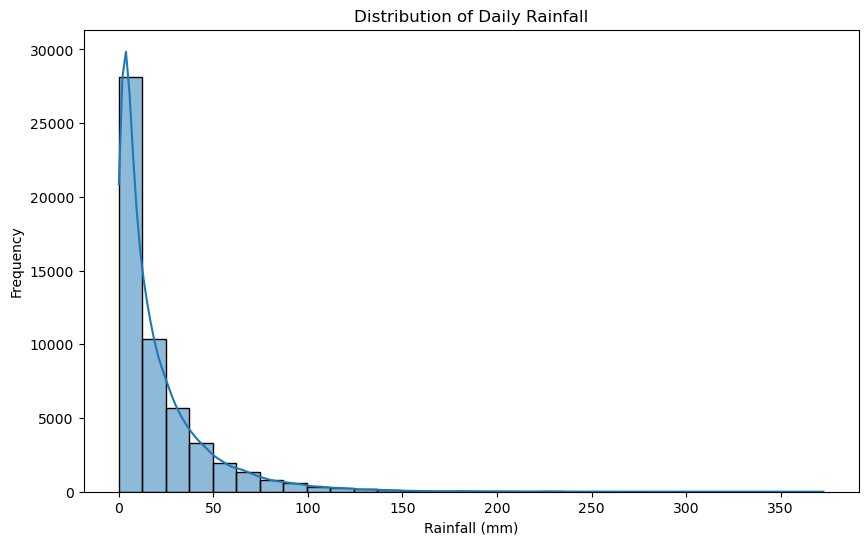

In [24]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df['Manual Daily Rainfall (mm)'],
    bins=30,
    kde=True
)

plt.title('Distribution of Daily Rainfall')
plt.xlabel('Rainfall (mm)')
plt.ylabel('Frequency')
plt.show()

**Observation:** The histogram shows how frequently different rainfall amounts occur and helps identify whether observations are concentrated around lower values or spread toward higher rainfall amounts.

## Q2.WHEN DO HEAVY RAINFALL EVENTS OCCUR MOST FREQUENTLY?


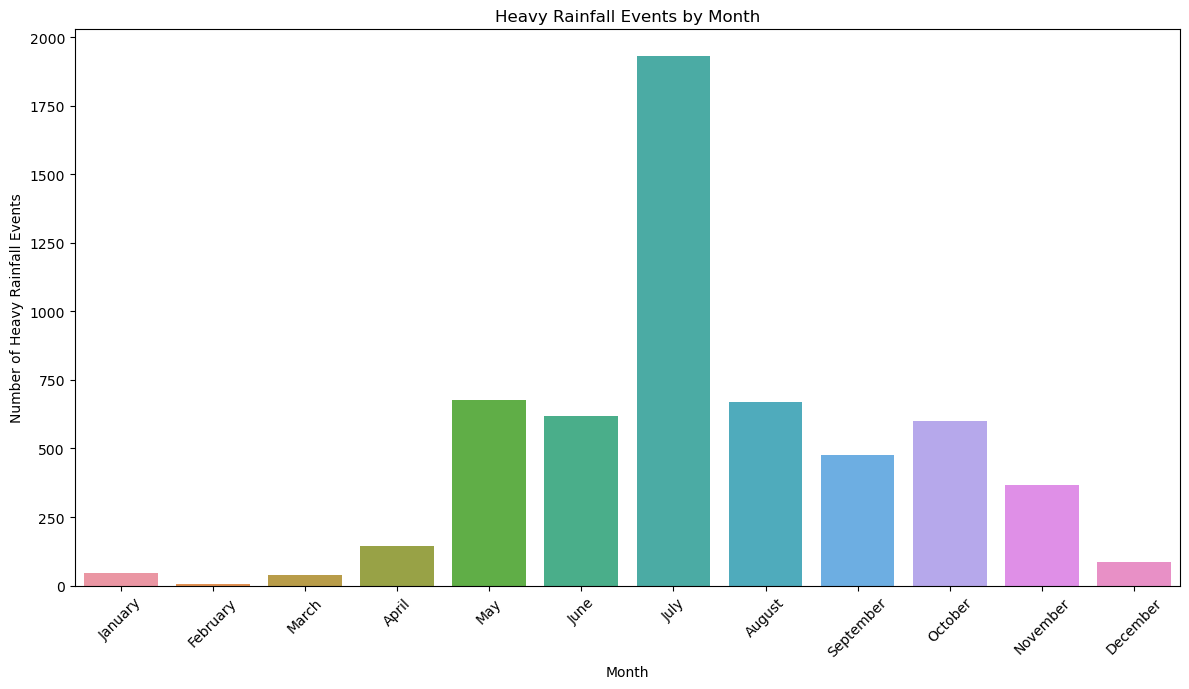

In [50]:
heavy_rainfall = df[df['Manual Daily Rainfall (mm)'] >= 50]

monthly_heavy_rainfall = (
    heavy_rainfall.groupby('Month_Name')
    .size()
    .reindex([
        'January', 'February', 'March', 'April', 'May', 'June',
        'July', 'August', 'September', 'October', 'November', 'December'
    ])
)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=monthly_heavy_rainfall.index,
    y=monthly_heavy_rainfall.values
)

plt.title('Heavy Rainfall Events by Month')
plt.xlabel('Month')
plt.ylabel('Number of Heavy Rainfall Events')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**Observation:** The chart shows how heavy rainfall events are distributed across the months. A higher number of events in a month indicates that heavy rainfall occurs more frequently during that period.

## Q3. HOW DOES THE NUMBER OF RAINFALL RECORDS VARY BY YEAR?

This shows the number of observations available for each year.

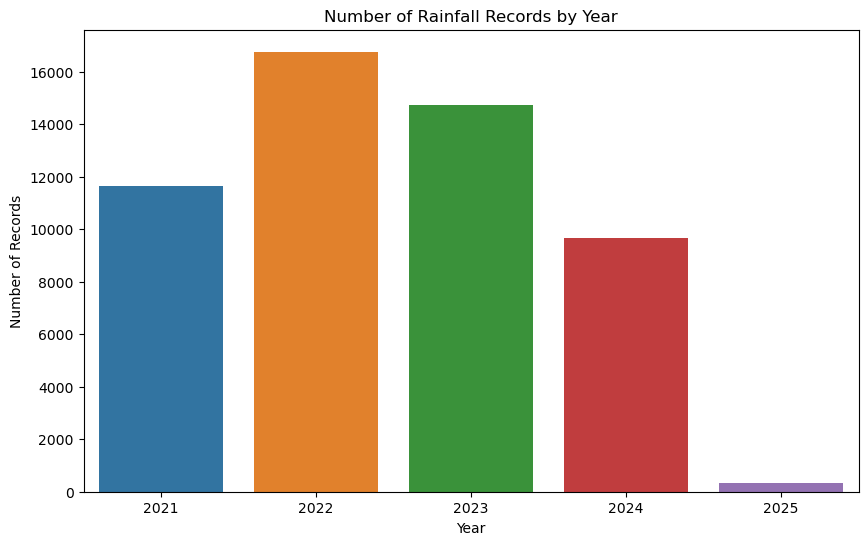

In [26]:
year_count = df['Year'].value_counts().sort_index()

plt.figure(figsize=(10, 6))
sns.barplot(x=year_count.index, y=year_count.values)

plt.title('Number of Rainfall Records by Year')
plt.xlabel('Year')
plt.ylabel('Number of Records')
plt.show()

**Observation:** This chart shows whether the number of recorded observations is consistent across the study period.

## Q4. HOW DOES AVERAGE RAINFALL CHANGE FROM YEAR TO YEAR?

Yearly average rainfall is compared using a line chart.

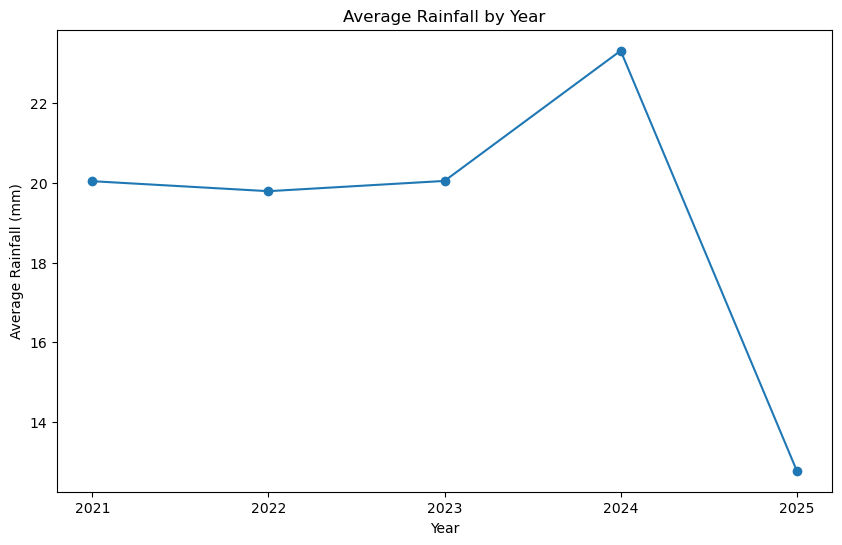

In [48]:
yearly_rainfall = (
    df.groupby('Year')['Manual Daily Rainfall (mm)']
    .mean()
)

plt.figure(figsize=(10, 6))
plt.plot(yearly_rainfall.index, yearly_rainfall.values, marker='o')

plt.title('Average Rainfall by Year')
plt.xlabel('Year')
plt.ylabel('Average Rainfall (mm)')
plt.xticks(yearly_rainfall.index)
plt.show()

**Observation:** The line chart shows how the average recorded daily rainfall changes between years.

## Q5. HOW DOES RAINFALL VARY ACROSS MONTHS?

Monthly averages are used to examine the overall seasonal pattern within the calendar year.

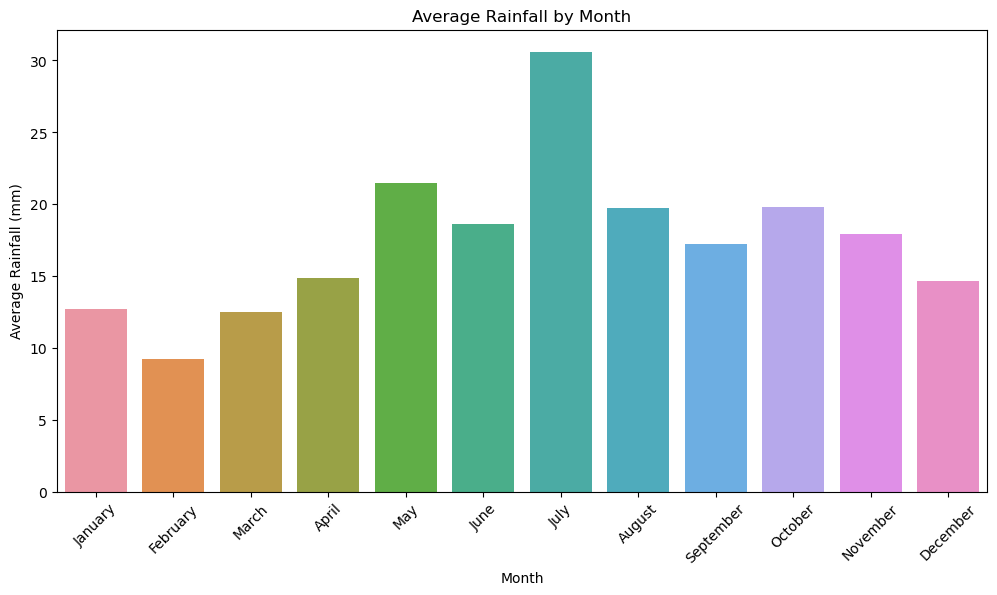

In [28]:
monthly_rainfall = (
    df.groupby(['Month', 'Month_Name'])['Manual Daily Rainfall (mm)']
    .mean()
    .reset_index()
    .sort_values('Month')
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=monthly_rainfall,
    x='Month_Name',
    y='Manual Daily Rainfall (mm)'
)

plt.title('Average Rainfall by Month')
plt.xlabel('Month')
plt.ylabel('Average Rainfall (mm)')
plt.xticks(rotation=45)
plt.show()

**Observation:** The monthly chart highlights the months with relatively higher and lower average recorded rainfall.

## Q6. HOW DOES MONTHLY RAINFALL VARY ACROSS YEARS?


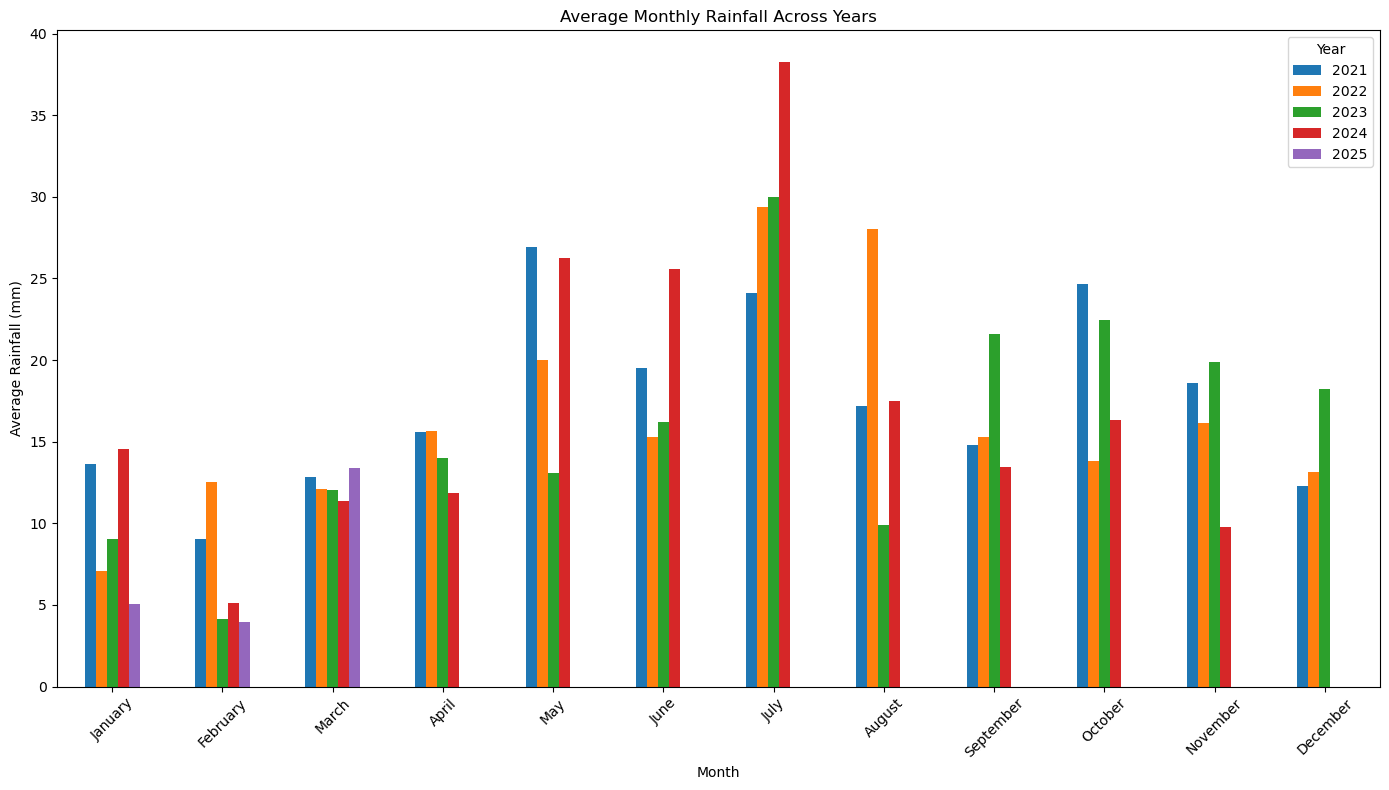

In [47]:
month_year = df.pivot_table(
    values='Manual Daily Rainfall (mm)',
    index='Month_Name',
    columns='Year',
    aggfunc='mean'
)

month_order = [
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
]

month_year = month_year.reindex(month_order)

# Create bar chart
month_year.plot(
    kind='bar',
    figsize=(14, 8)
)

plt.title('Average Monthly Rainfall Across Years')
plt.xlabel('Month')
plt.ylabel('Average Rainfall (mm)')
plt.xticks(rotation=45)
plt.legend(title='Year')
plt.tight_layout()

plt.show()

**Observation:** The heatmap makes it easier to compare rainfall intensity for the same month across different years.

## Q7. HOW DOES RAINFALL DISTRIBUTION VARY BY SEASON?

Season-wise average rainfall is compared.

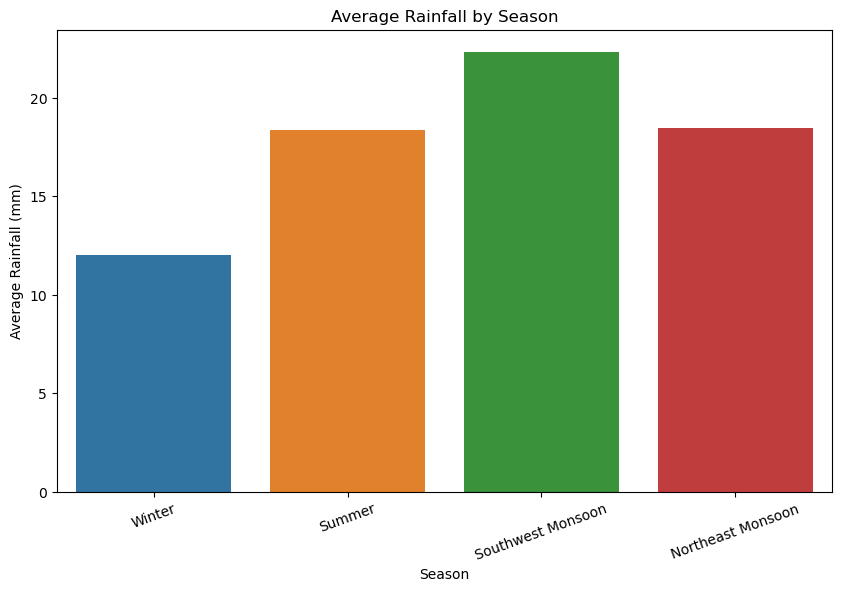

In [30]:
season_rainfall = (
    df.groupby('Season')['Manual Daily Rainfall (mm)']
    .mean()
    .reindex(['Winter', 'Summer', 'Southwest Monsoon', 'Northeast Monsoon'])
)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=season_rainfall.index,
    y=season_rainfall.values
)

plt.title('Average Rainfall by Season')
plt.xlabel('Season')
plt.ylabel('Average Rainfall (mm)')
plt.xticks(rotation=20)
plt.show()

**Observation:** The chart compares average rainfall between the defined seasons and shows the dominant rainfall periods.

## Q8. HOW DOES SEASONAL RAINFALL CHANGE ACROSS YEARS?

A heatmap is used to compare each season across the five years.

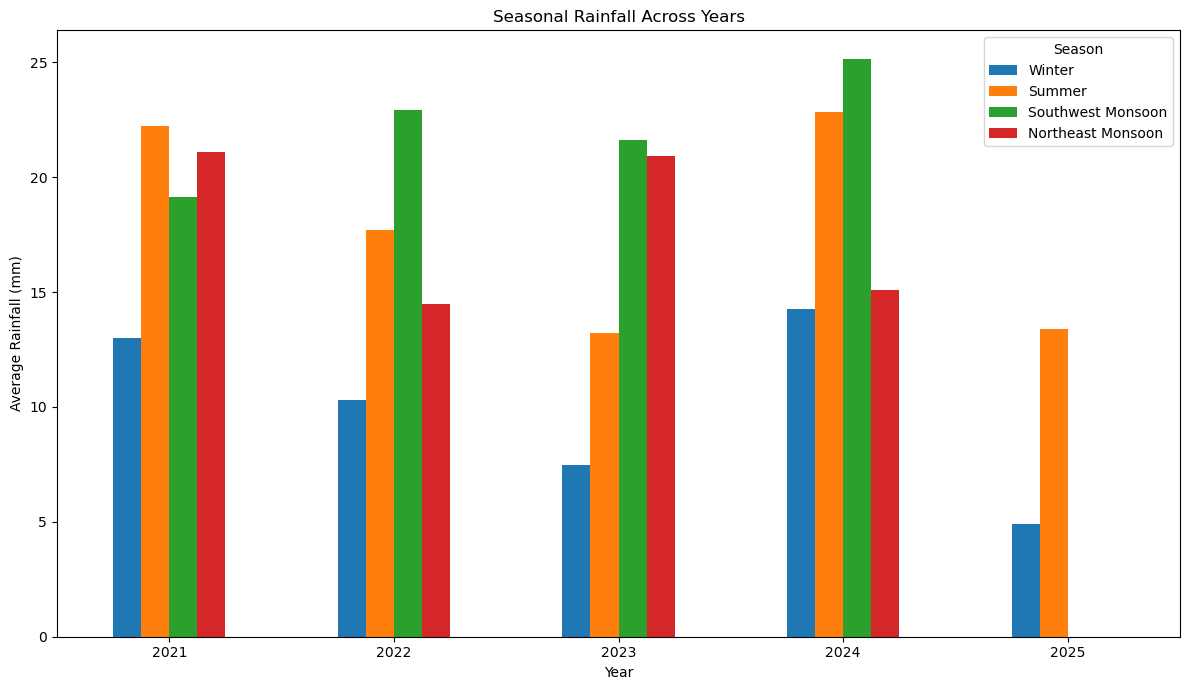

In [46]:
season_year = df.pivot_table(
    values='Manual Daily Rainfall (mm)',
    index='Season',
    columns='Year',
    aggfunc='mean'
)

season_year = season_year.reindex(
    ['Winter', 'Summer', 'Southwest Monsoon', 'Northeast Monsoon']
)

# Convert to grouped bar chart
season_year.T.plot(
    kind='bar',
    figsize=(12, 7)
)

plt.title('Seasonal Rainfall Across Years')
plt.xlabel('Year')
plt.ylabel('Average Rainfall (mm)')
plt.xticks(rotation=0)
plt.legend(title='Season')
plt.tight_layout()

plt.show()

**Observation:** The heatmap helps identify years in which particular seasons had relatively higher or lower average rainfall.

## Q9. HOW DOES THE SOUTHWEST MONSOON VARY ACROSS YEARS?

The Southwest Monsoon period is defined as June–September.

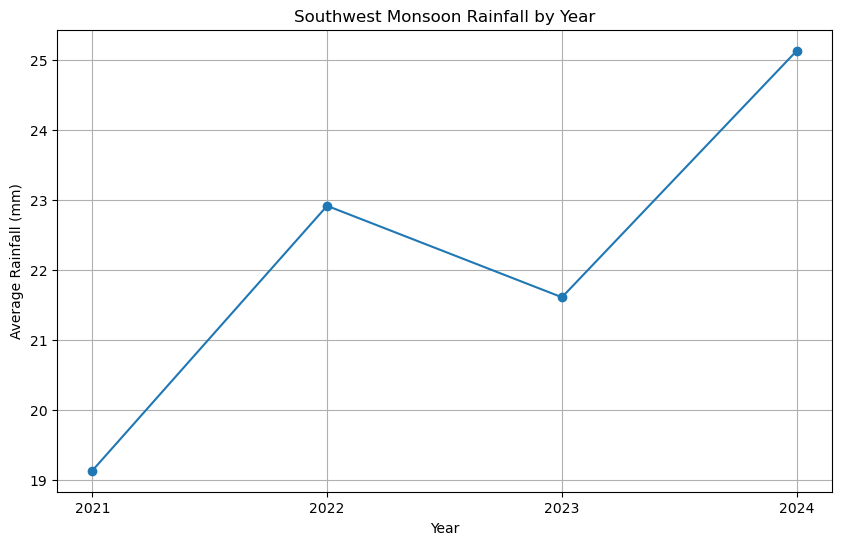

In [32]:
sw_monsoon = df[df['Month'].isin([6, 7, 8, 9])]

sw_yearly = (
    sw_monsoon.groupby('Year')['Manual Daily Rainfall (mm)']
    .mean()
)

plt.figure(figsize=(10, 6))
plt.plot(sw_yearly.index, sw_yearly.values, marker='o')

plt.title('Southwest Monsoon Rainfall by Year')
plt.xlabel('Year')
plt.ylabel('Average Rainfall (mm)')
plt.xticks(sw_yearly.index)
plt.grid(True)
plt.show()

**Observation:** The line chart shows year-to-year variation in average rainfall during the Southwest Monsoon period.

## Q10. HOW DOES THE NORTHEAST MONSOON VARY ACROSS YEARS?

The Northeast Monsoon period is defined as October–December.

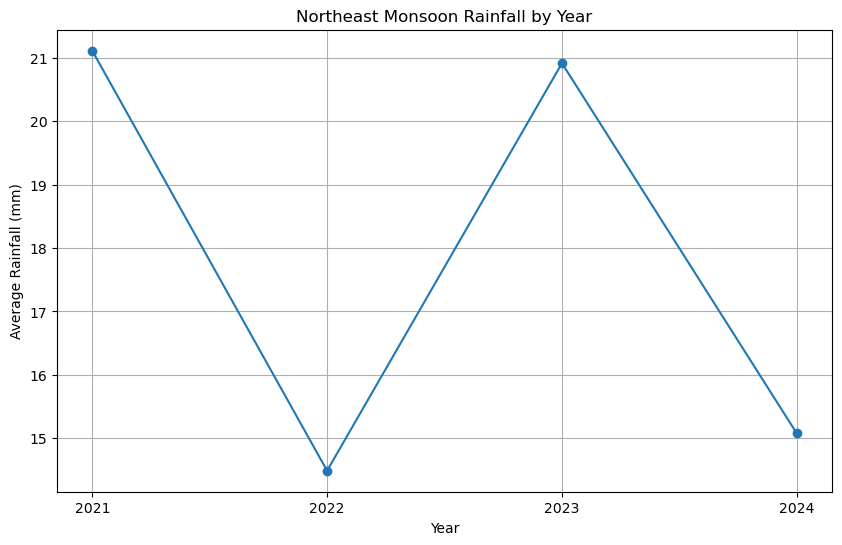

In [33]:
ne_monsoon = df[df['Month'].isin([10, 11, 12])]

ne_yearly = (
    ne_monsoon.groupby('Year')['Manual Daily Rainfall (mm)']
    .mean()
)

plt.figure(figsize=(10, 6))
plt.plot(ne_yearly.index, ne_yearly.values, marker='o')

plt.title('Northeast Monsoon Rainfall by Year')
plt.xlabel('Year')
plt.ylabel('Average Rainfall (mm)')
plt.xticks(ne_yearly.index)
plt.grid(True)
plt.show()

**Observation:** The chart shows how Northeast Monsoon rainfall changes across the study period.

## Q11. HOW DO THE TWO MONSOON PERIODS COMPARE?

Southwest and Northeast Monsoon averages are compared year by year.

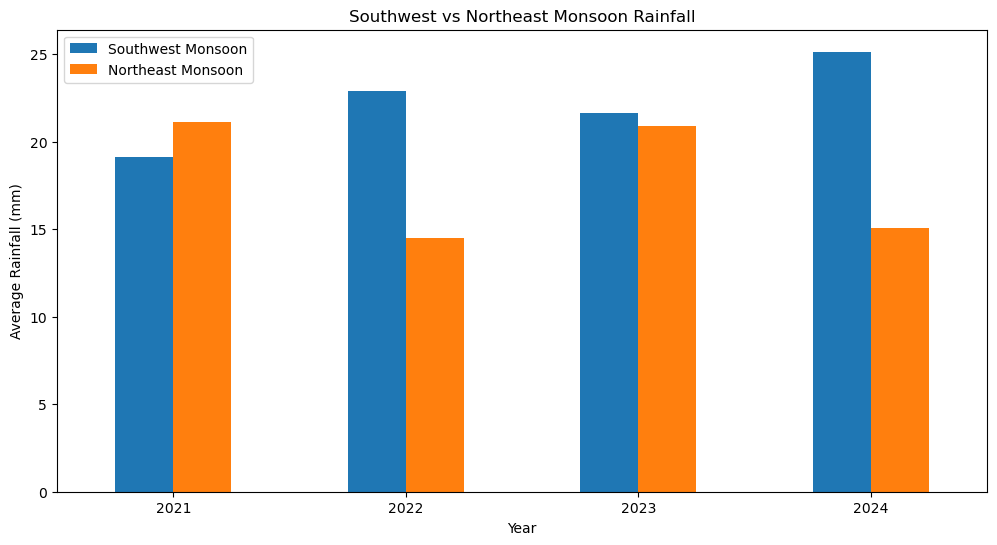

In [34]:
monsoon_comparison = pd.DataFrame({
    'Southwest Monsoon': sw_yearly,
    'Northeast Monsoon': ne_yearly
})

monsoon_comparison.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Southwest vs Northeast Monsoon Rainfall')
plt.xlabel('Year')
plt.ylabel('Average Rainfall (mm)')
plt.xticks(rotation=0)
plt.show()

**Observation:** The comparison shows which monsoon period records higher average rainfall in each year.

## Q12. HOW DOES AVERAGE RAINFALL VARY ACROSS DISTRICTS?

District-wise average rainfall is compared using a horizontal bar chart.

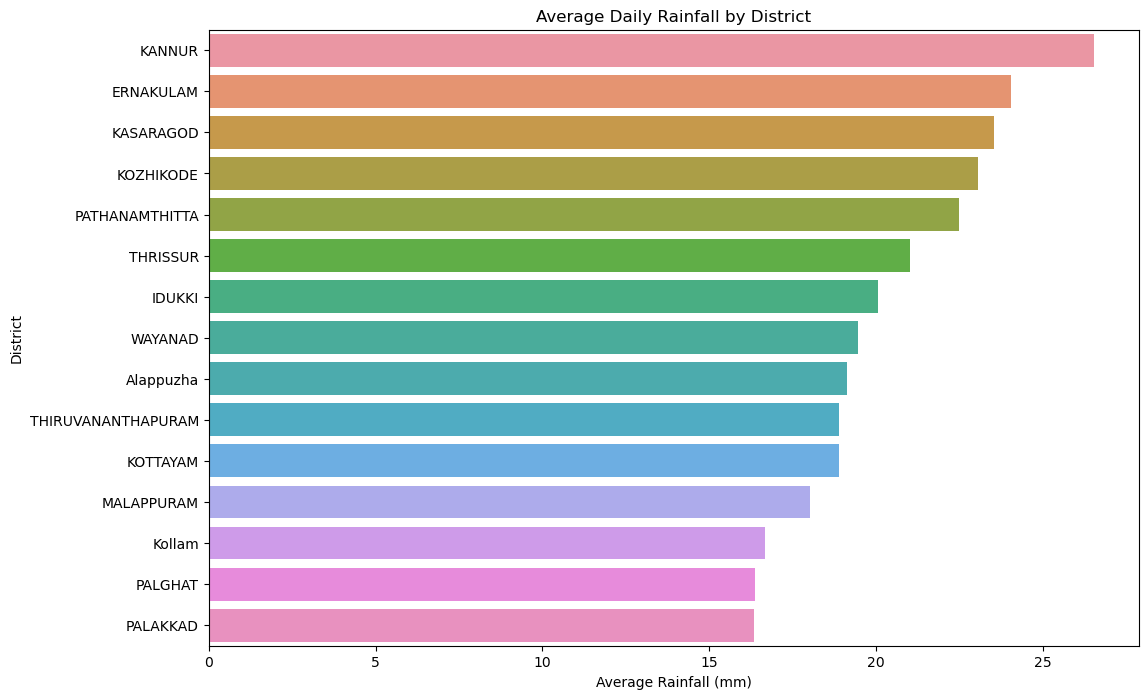

In [35]:
district_rainfall = (
    df.groupby('District')['Manual Daily Rainfall (mm)']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 8))
sns.barplot(
    x=district_rainfall.values,
    y=district_rainfall.index
)

plt.title('Average Daily Rainfall by District')
plt.xlabel('Average Rainfall (mm)')
plt.ylabel('District')
plt.show()

**Observation:** District-level comparison highlights geographical differences in average recorded rainfall.

## Q13. HOW DOES DISTRICT-WISE RAINFALL CHANGE ACROSS YEARS?

A district × year heatmap is used to compare the yearly pattern of districts.

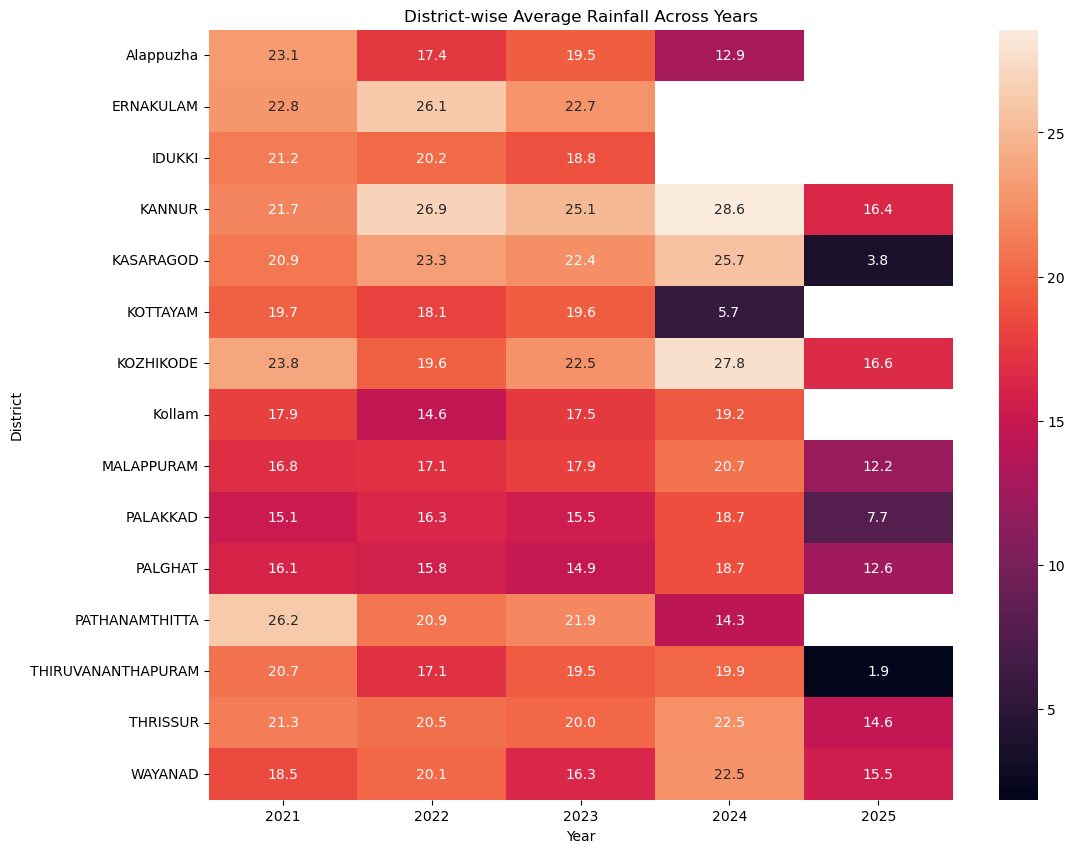

In [36]:
district_year = df.pivot_table(
    values='Manual Daily Rainfall (mm)',
    index='District',
    columns='Year',
    aggfunc='mean'
)

plt.figure(figsize=(12, 10))
sns.heatmap(district_year, annot=True, fmt='.1f')

plt.title('District-wise Average Rainfall Across Years')
plt.xlabel('Year')
plt.ylabel('District')
plt.show()

**Observation:** The heatmap shows how rainfall levels differ among districts and how those levels change over the study period.

## Q14. DO DISTRICTS HAVE DIFFERENT RAINFALL DISTRIBUTIONS?

A box plot is used to compare the distribution of rainfall among districts.

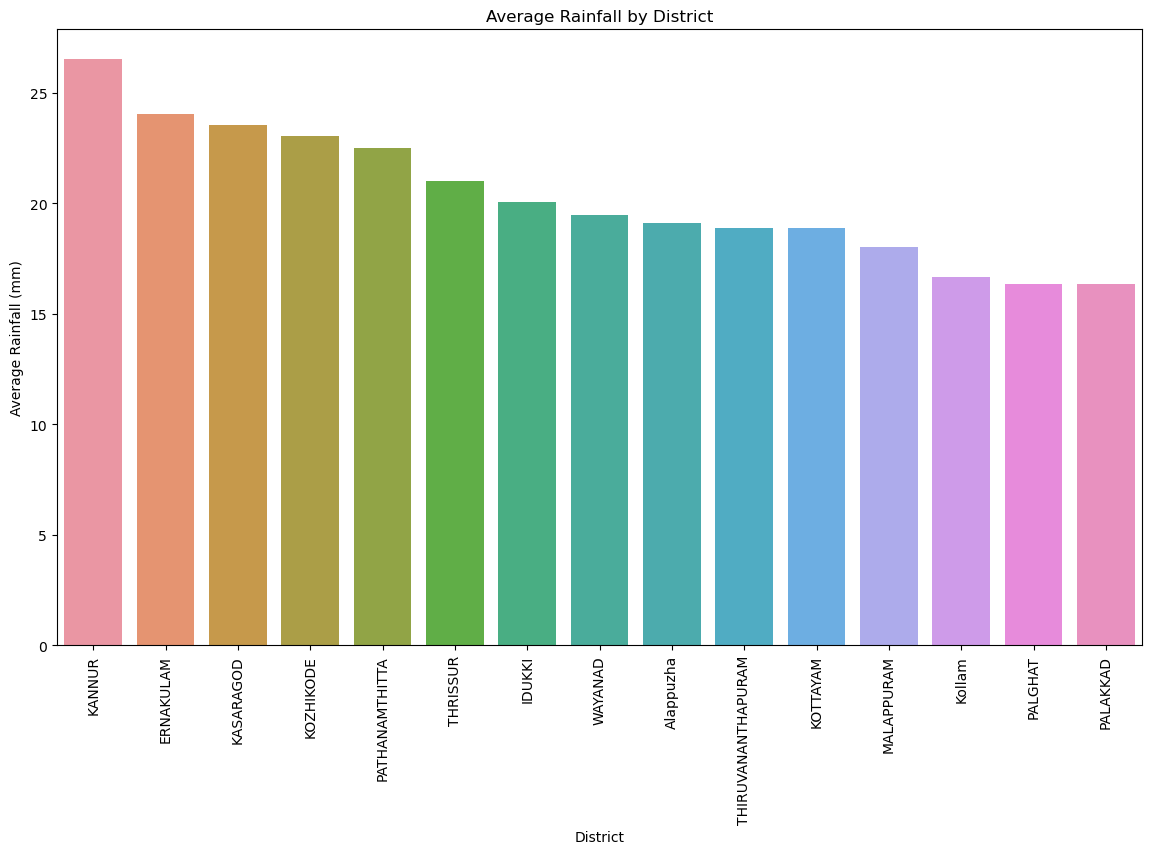

In [45]:
district_rainfall = (
    df.groupby('District')['Manual Daily Rainfall (mm)']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(14, 8))

sns.barplot(
    x=district_rainfall.index,
    y=district_rainfall.values
)

plt.title('Average Rainfall by District')
plt.xlabel('District')
plt.ylabel('Average Rainfall (mm)')
plt.xticks(rotation=90)

plt.show()

**Observation:** The box plots show differences in median rainfall, spread, and potential extreme observations between districts.

## Q15. WHICH DISTRICTS SHOW THE GREATEST RAINFALL VARIABILITY?

Standard deviation is used as a measure of rainfall variability.

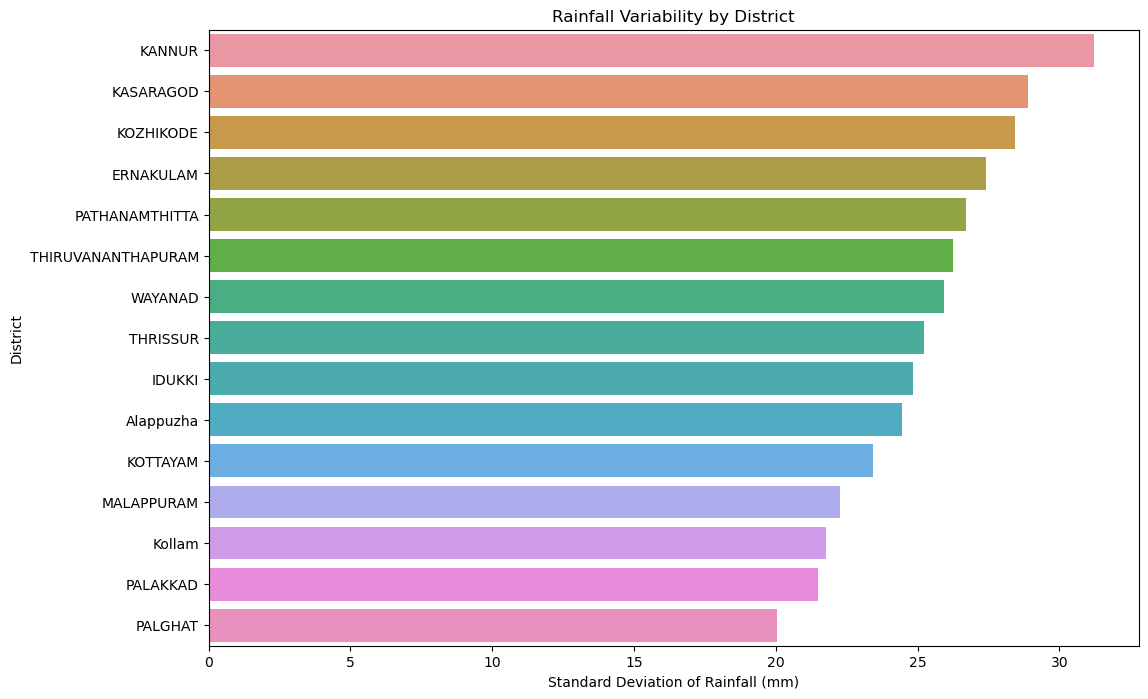

In [38]:
district_variability = (
    df.groupby('District')['Manual Daily Rainfall (mm)']
    .std()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 8))
sns.barplot(
    x=district_variability.values,
    y=district_variability.index
)

plt.title('Rainfall Variability by District')
plt.xlabel('Standard Deviation of Rainfall (mm)')
plt.ylabel('District')
plt.show()

**Observation:** Districts with higher standard deviation have greater variation in their recorded daily rainfall.

## Q16. HOW DOES DAILY RAINFALL CHANGE OVER TIME?

Daily average rainfall is plotted as a time series.

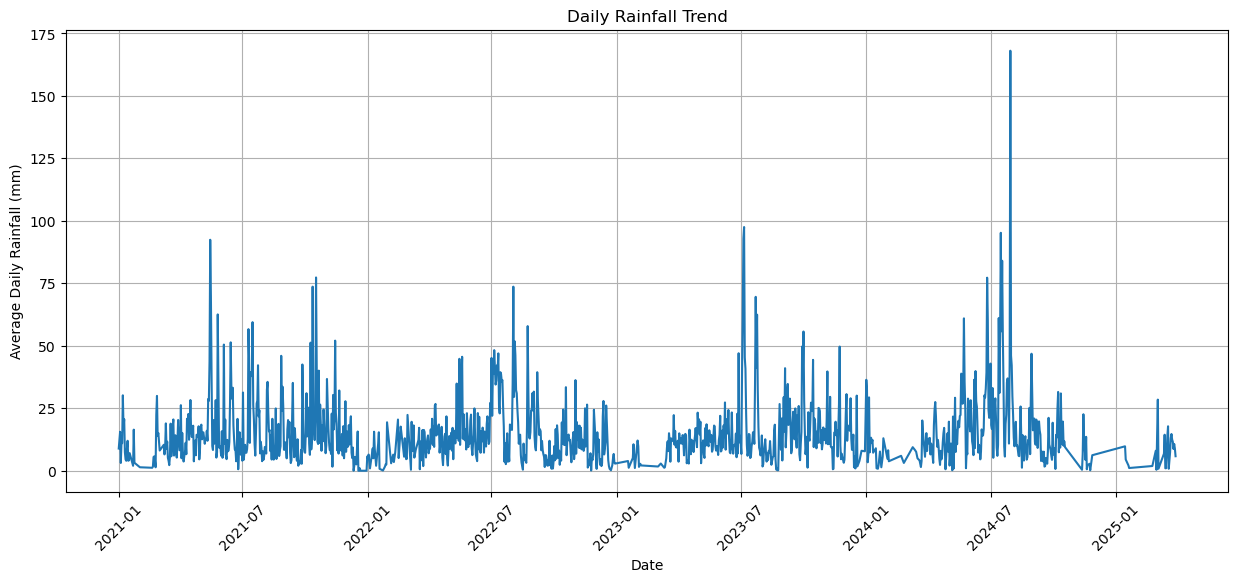

In [39]:
daily_rainfall = (
    df.groupby('Date')['Manual Daily Rainfall (mm)']
    .mean()
)

plt.figure(figsize=(15, 6))
plt.plot(daily_rainfall.index, daily_rainfall.values)

plt.title('Daily Rainfall Trend')
plt.xlabel('Date')
plt.ylabel('Average Daily Rainfall (mm)')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

**Observation:** The time-series plot shows short-term rainfall fluctuations and periods with higher rainfall activity.

## Q17. WHEN DO HEAVY RAINFALL EVENTS OCCUR MOST FREQUENTLY?

For this analysis, rainfall of **50 mm or more** is classified as a heavy rainfall event.

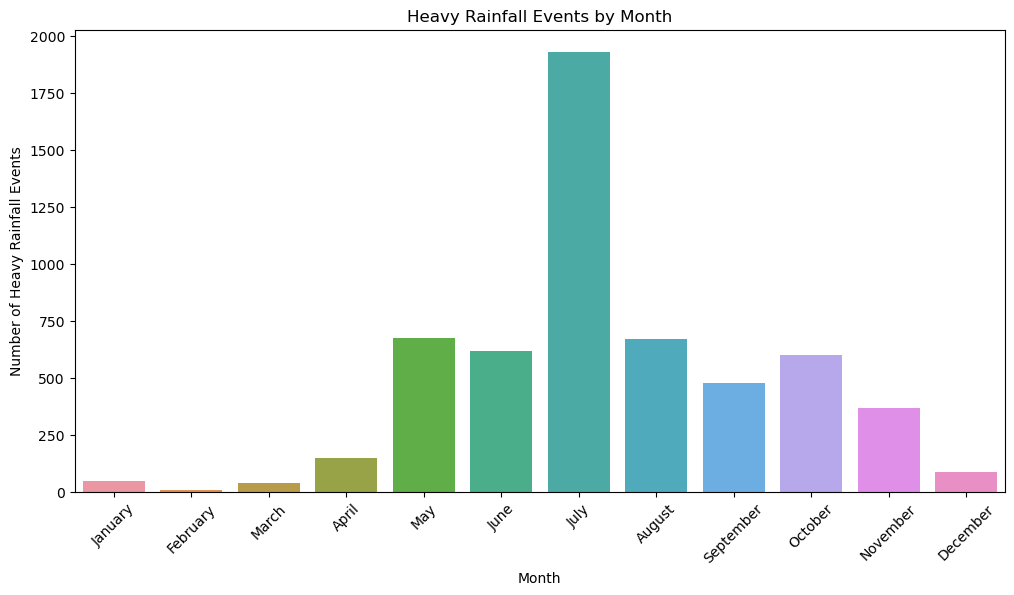

In [40]:
heavy_rainfall = df[
    df['Manual Daily Rainfall (mm)'] >= 50
]

heavy_by_month = (
    heavy_rainfall.groupby(['Month', 'Month_Name'])
    .size()
    .reset_index(name='Count')
    .sort_values('Month')
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=heavy_by_month,
    x='Month_Name',
    y='Count'
)

plt.title('Heavy Rainfall Events by Month')
plt.xlabel('Month')
plt.ylabel('Number of Heavy Rainfall Events')
plt.xticks(rotation=45)
plt.show()

**Observation:** The chart identifies the months in which heavy rainfall observations occur most frequently under the chosen 50 mm threshold.

## Q18. HOW DOES THE FREQUENCY OF HEAVY RAINFALL EVENTS CHANGE BY YEAR?

Heavy rainfall observations are counted for each year.

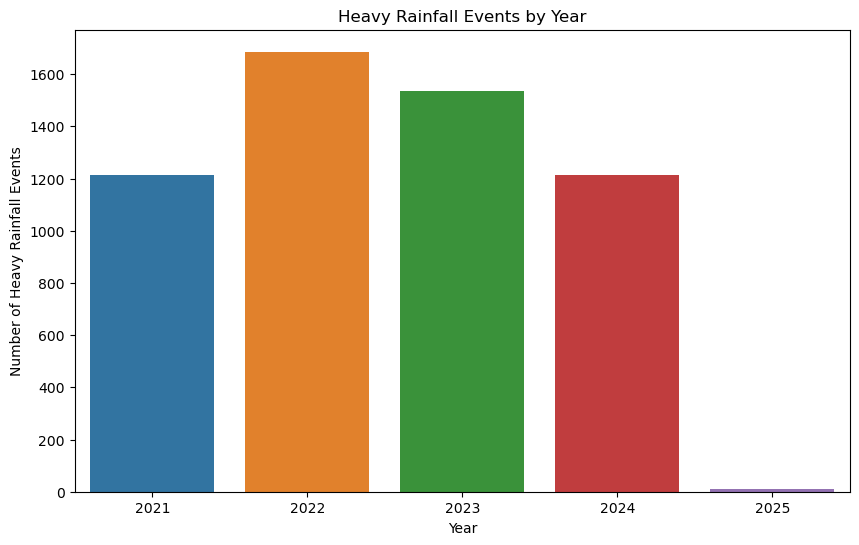

In [41]:
heavy_by_year = (
    heavy_rainfall.groupby('Year')
    .size()
)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=heavy_by_year.index,
    y=heavy_by_year.values
)

plt.title('Heavy Rainfall Events by Year')
plt.xlabel('Year')
plt.ylabel('Number of Heavy Rainfall Events')
plt.xticks(rotation=0)
plt.show()

**Observation:** The yearly comparison shows which years contain more or fewer observations meeting the heavy-rainfall threshold.

## Q19. WHICH DISTRICTS EXPERIENCE MORE HEAVY RAINFALL EVENTS?

The number of heavy rainfall observations is compared across districts.

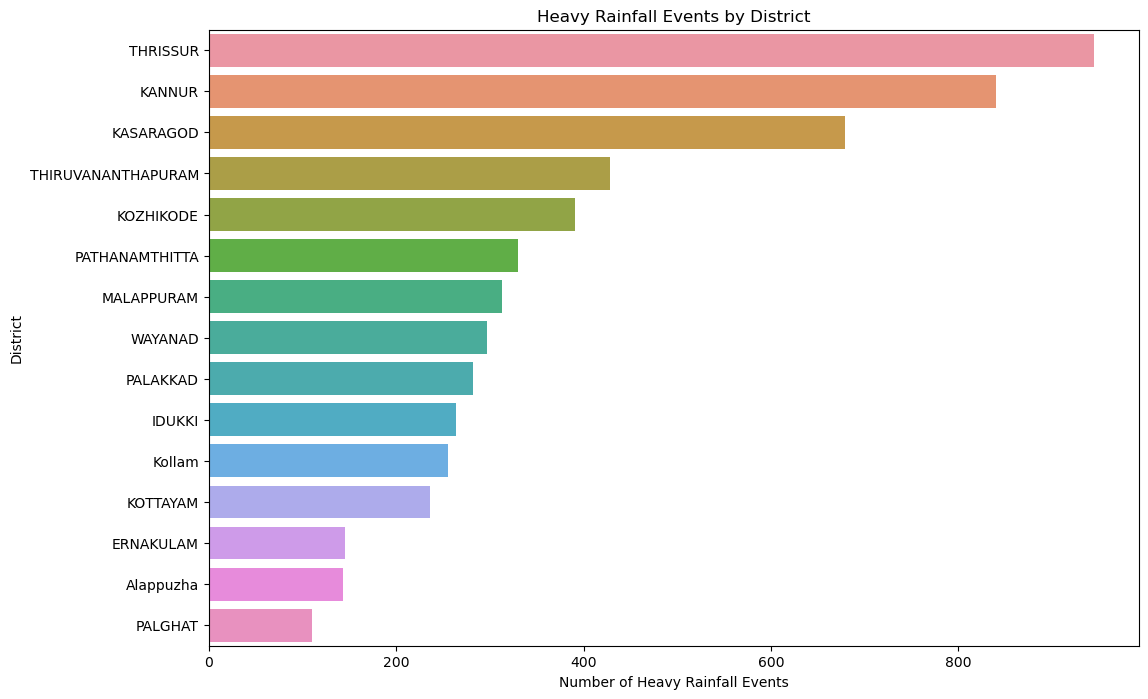

In [42]:
heavy_by_district = (
    heavy_rainfall.groupby('District')
    .size()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 8))
sns.barplot(
    x=heavy_by_district.values,
    y=heavy_by_district.index
)

plt.title('Heavy Rainfall Events by District')
plt.xlabel('Number of Heavy Rainfall Events')
plt.ylabel('District')
plt.show()

**Observation:** The district comparison identifies areas with more frequent observations at or above the heavy-rainfall threshold.

## Q20. WHAT ARE THE MOST EXTREME RAINFALL OBSERVATIONS?

The ten highest rainfall observations are displayed.

In [43]:
top_10_extreme = df.nlargest(
    10,
    'Manual Daily Rainfall (mm)'
)[[
    'Data Acquisition Time',
    'Station',
    'District',
    'Manual Daily Rainfall (mm)'
]]

top_10_extreme

,Data Acquisition Time,Station,District,Manual Daily Rainfall (mm)
15222,2024-07-30 08:00:00,Kalladi,WAYANAD,372.6
28020,2024-07-30 08:00:00,NELLIAMPATHY,PALAKKAD,322.0
50904,2024-07-30 08:00:00,Vazhani,THRISSUR,300.0
5448,2021-10-17 08:30:00,BOYCE ESTATE,IDUKKI,290.4
8878,2024-07-30 08:00:00,Chittady,THRISSUR,288.8
43651,2024-07-30 08:00:00,Thamarassery,KOZHIKODE,283.6
6791,2021-12-01 08:30:00,Cherthala,Alappuzha,270.0
23465,2024-07-30 08:00:00,Maloor,KANNUR,266.4
30222,2023-07-06 08:00:00,Olayampadi,KANNUR,260.4
40571,2024-07-30 08:00:00,Pothundy Dam,PALGHAT,255.0


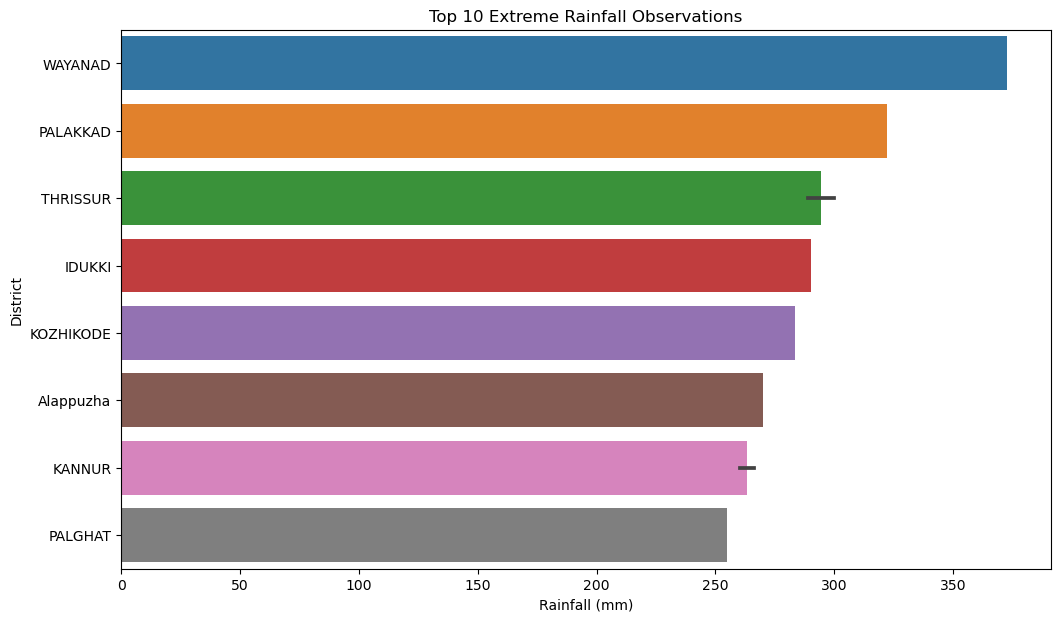

In [44]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_extreme,
    x='Manual Daily Rainfall (mm)',
    y='District'
)

plt.title('Top 10 Extreme Rainfall Observations')
plt.xlabel('Rainfall (mm)')
plt.ylabel('District')
plt.show()

**Observation:** These observations represent the highest recorded daily rainfall values in the dataset and can be examined as extreme rainfall events.

## Q21. WHICH YEAR HAD THE HIGHEST AVERAGE RAINFALL?

In [54]:
yearly_rainfall = df.groupby('Year')['Manual Daily Rainfall (mm)'].mean()

wettest_year = yearly_rainfall.idxmax()
print("Wettest Year:", wettest_year)


Wettest Year: 2024


## Q22. WHICH YEAR HAD THE LOWEST AVERAGE RAINFALL?

In [53]:
driest_year = yearly_rainfall.idxmin()

print("Driest Year:", driest_year)

Driest Year: 2025


## Q23. WHICH MONTH HAD THE HIGHEST AVERAGE RAINFALL?

In [55]:
monthly_rainfall = df.groupby(
    'Month_Name'
)['Manual Daily Rainfall (mm)'].mean()

wettest_month = monthly_rainfall.idxmax()

print("Wettest Month:", wettest_month)

Wettest Month: July


## Q24. WHICH DISTRICT HAD THE HIGHEST AVERAGE RAINFALL?

In [56]:
district_rainfall = df.groupby(
    'District'
)['Manual Daily Rainfall (mm)'].mean()

wettest_district = district_rainfall.idxmax()

print("Wettest District:", wettest_district)

Wettest District: KANNUR


## Q25. WHICH DISTRICT HAD THE LOWEST AVERAGE RAINFALL?

In [57]:
lowest_rainfall_district = district_rainfall.idxmin()

print("Lowest Rainfall District:", lowest_rainfall_district)

Lowest Rainfall District: PALAKKAD


# KEY INSIGHTS

The EDA provides a broad view of rainfall behavior across Kerala during the study period. The analysis examines yearly, monthly, seasonal, monsoon, district-wise, and extreme-rainfall patterns.

The exact highest and lowest values should be taken from the outputs generated by the notebook. The charts can be used to identify periods of higher rainfall, seasonal concentration, district-level differences, and extreme rainfall observations.

# CONCLUSION

This project demonstrates how Exploratory Data Analysis can be used to understand rainfall patterns in Kerala. Using Python, the dataset was examined through data cleaning, feature creation, statistical analysis, and multiple visualizations.

The analysis provides insights into how rainfall varies across years, months, seasons, monsoon periods, and districts. It also highlights rainfall variability and heavy or extreme rainfall observations.

Such analysis can support further work in rainfall forecasting, agricultural planning, water-resource management, and disaster preparedness. The project can also be extended with statistical modelling or machine learning to predict future rainfall patterns.